<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%204/logo.png" width="300" alt="cognitiveclass.ai logo">
</center>

# Waffle Charts, Word Clouds, and Regression Plots

Estimated time needed: **40** minutes

## Objectives

After completing this lab you will be able to:

*   Create Word cloud and Waffle charts
*   Create regression plots with Seaborn library


## Table of Contents

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Import Libraries](#0)<br>
2.  [Fetching Data](#1)<br>
3.  [Waffle Charts](#3) <br>
4.  [Word Clouds](#4) <br>
5.  [Ploting with Seaborn](#5) <br>
6.  [Regression Plots](#6) <br>

</div>


# Import Libraries<a id="0"></a>


In [1]:
!pip install matplotlib
!pip install pandas

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
#Import and setup matplotlib:
# 这一段代码是Module3导入库的操作，不需要任何修改，直接运行即可：
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # needed for waffle Charts
mpl.style.use('ggplot') # optional: for ggplot-like style
#Import Primary Modules:
import numpy as np  # useful for many scientific computing in Python
import pandas as pd # primary data structure library
from PIL import Image # converting images into arrays
#install seaborn and wordcloud
!pip install seaborn wordcloud 
#import seaborn
import seaborn as sns
#import wordcloud
import wordcloud
# check for latest version of Matplotlib and seaborn
print ('Matplotlib version: ', mpl.__version__) # >= 2.0.0
print('Seaborn version: ', sns.__version__)
print('WordCloud version: ', wordcloud.__version__)
# 根据打印的版本号可以知道，下面画图所需要的所有的库都已经成功导入：

Defaulting to user installation because normal site-packages is not writeable
Matplotlib version:  3.11.0
Seaborn version:  0.13.2
WordCloud version:  1.9.6


# Fetching Data<a id="1"></a>

Toolkits: The course heavily relies on [*pandas*](http://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) and [*Numpy*](http://www.numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) for data wrangling, analysis, and visualization. The primary plotting library we will explore in the course is [Matplotlib](http://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).

Dataset: Immigration to Canada from 1980 to 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) from United Nation's website

The dataset contains annual data on the flows of international migrants as recorded by the countries of destination. The data presents both inflows and outflows according to the place of birth, citizenship or place of previous / next residence both for foreigners and nationals. <br><br>In this lab, we will focus on the Canadian Immigration data and use the *already cleaned dataset*.<br><br>
You can refer to the lab on data pre-processing wherein this dataset is cleaned for a quick refresh your Panads skill [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/v4/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)



Download the Canadian Immigration dataset and read it into a *pandas* dataframe.


In [3]:
# 下一步，导入数据。这个module依然使用的是加拿大移民数据。
# 所以我们将数据集命名为 Canada_immigration :
Canada_immigration = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv')
print('Data read into a pandas dataframe!')
# 从输出结果可见，数据集已经成功导入。

Data read into a pandas dataframe!


Let's take a look at the first five items in our dataset


In [4]:
# 如果还不放心的话，就可以打印数据的前五行。
# 对数据集使用 head（）函数，括号里填数字5.
Canada_immigration.head(5)

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Let's find out how many entries there are in our dataset


In [5]:
# print the dimensions of the dataframe
# 想进一步检查数据有多少行多少列，有两种方法：
# 第一种是直接使用shape属性，同时调取行列数；
print(Canada_immigration.shape)
# 第二种方法是分别对 行和列使用 len()函数去计数：
print("The Number of Rows in this dataset:", len(Canada_immigration) )
print("The Number of Columns in this dataset:", len(Canada_immigration.columns))
# 从输出结果可以看到，都是195行39列，数据完全导入成功。

(195, 39)
The Number of Rows in this dataset: 195
The Number of Columns in this dataset: 39


In [6]:
#set Country as index
# 下一步，为方便画图，将国家名Country设置为索引。
Canada_immigration.set_index('Country', inplace = True)
# 可以看看，设置之后的数据量发生了什么变化：
print(Canada_immigration.shape)
# 列减少了一行。说明成功设置。

(195, 38)


# Waffle Charts <a id="3"></a>

A `waffle chart` is an interesting visualization that is normally created to display progress toward goals. It is commonly an effective option when you are trying to add interesting visualization features to a visual that consists mainly of cells, such as an Excel dashboard.


Let's revisit the previous case study about Denmark, Norway, and Sweden.


In [8]:
# let's create a new dataframe for these three countries 
# 我们重新回顾之前关于丹麦、挪威和瑞典的案例研究。对数据集使用loc索引功能，提取他们三个国家的数据：
# 将新的变量命名为 Canada_immigration_DSN
Canada_immigration_DSN = Canada_immigration.loc[['Denmark', 'Norway', 'Sweden'], :]
# let's take a look at our dataframe
# 然后打印检查数据集：
Canada_immigration_DSN

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Denmark,Europe,Northern Europe,Developed regions,272,293,299,106,93,73,93,...,62,101,97,108,81,92,93,94,81,3901
Norway,Europe,Northern Europe,Developed regions,116,77,106,51,31,54,56,...,57,53,73,66,75,46,49,53,59,2327
Sweden,Europe,Northern Europe,Developed regions,281,308,222,176,128,158,187,...,205,139,193,165,167,159,134,140,140,5866


Unfortunately, unlike R, `waffle` charts are not built into any of the Python visualization libraries. Therefore, we will learn how to create them from scratch.


**Step 1.** The first step into creating a waffle chart is determing the proportion of each category with respect to the total.


In [13]:
# compute the proportion of each category with respect to the total
# 不幸的是，与R语言不同，Waffle图表并未内置在任何Python可视化库中。因此，我们将学习如何从零开始创建它们。
# 步骤1： 创建华夫饼图的第一步，是确定每个类别相对于总数的比例。
# 所以先计算这三个国家的移民总量，对total求和，使用sum()函数求和：
# 将变量命名为 total_immigration_values_DSN:
total_immigration_DSN = Canada_immigration_DSN['Total']
total_immigration_values_DSN = total_immigration_DSN.sum()
# 然后求比例，就是用各自国家的total值，除以上面的总值：
# 将新的变量命名为 
category_proportions_of_DSN = total_immigration_DSN / total_immigration_values_DSN
# print out proportions
pd.DataFrame({"Category Proportion": category_proportions_of_DSN})

,Category Proportion
Country,
Denmark,0.322557
Norway,0.192409
Sweden,0.485034


**Step 2.** The second step is defining the overall size of the `waffle` chart.


In [14]:
# 第二步是定义华夫饼图的整体大小。
# 主要就是设置三个参数： width、height、total_num_tiles瓷砖数量，就是每个组成华夫饼图的元素:
width = 40 # width of chart
height = 10 # height of chart
total_num_tiles = width * height # total number of tiles
# 然后将宽乘高的结果，打印出来，检查华夫饼一共有几块元素：
print(f'Total number of tiles is {total_num_tiles}.')

Total number of tiles is 400.


**Step 3.** The third step is using the proportion of each category to determe it respective number of tiles


In [15]:
# compute the number of tiles for each category
# 第三步是使用每个国家的比例，来确定相应的瓷砖数量：
# 将新变量命名为 tiles_for_each_country，计算方式是 每个国家的比例，乘以华夫饼块总数。
# 最后不要忘记将它转成整数，再套一个round()函数。
tiles_for_each_country = (category_proportions_of_DSN * total_num_tiles).round().astype(int)
# 最后，打印出每个国家拥有的华夫饼元素数：
# print out number of tiles per category
pd.DataFrame({"Number of tiles": tiles_for_each_country })

,Number of tiles
Country,
Denmark,129
Norway,77
Sweden,194


Based on the calculated proportions, Denmark will occupy 129 tiles of the `waffle` chart, Norway will occupy 77 tiles, and Sweden will occupy 194 tiles.


**Step 4.** The fourth step is creating a matrix that resembles the `waffle` chart and populating it.


In [17]:
# 第四步，是创建一个类似于华夫饼图的矩阵，并填充它。
# initialize the waffle chart as an empty matrix，将这个矩阵命名为 waffle_chart_DSN
waffle_chart_DSN = np.zeros((height, width), dtype = np.uint)
# define indices to loop through waffle chart
category_index = 0
tile_index = 0
# 初始化设置两个参数 category_index、tile_index = 0；
# populate the waffle chart
# 将他们填充：
for col in range(width):
    for row in range(height):
        tile_index += 1
        # if the number of tiles populated for the current category is equal to its corresponding allocated tiles...
        if tile_index > sum(tiles_for_each_country [0:category_index]):
            # ...proceed to the next category
            category_index += 1       
        # set the class value to an integer, which increases with class
        waffle_chart_DSN[row, col] = category_index
print ('Waffle chart populated!')
# 在这一步之后，华夫饼图对应的矩阵就生成了。直接打印图像：

Waffle chart populated!


Let's take a peek at how the matrix looks like.


In [18]:
waffle_chart_DSN

array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

As expected, the matrix consists of three categories and the total number of each category's instances matches the total number of tiles allocated to each category.


**Step 5.** Map the `waffle` chart matrix into a visual.


<Figure size 640x480 with 0 Axes>

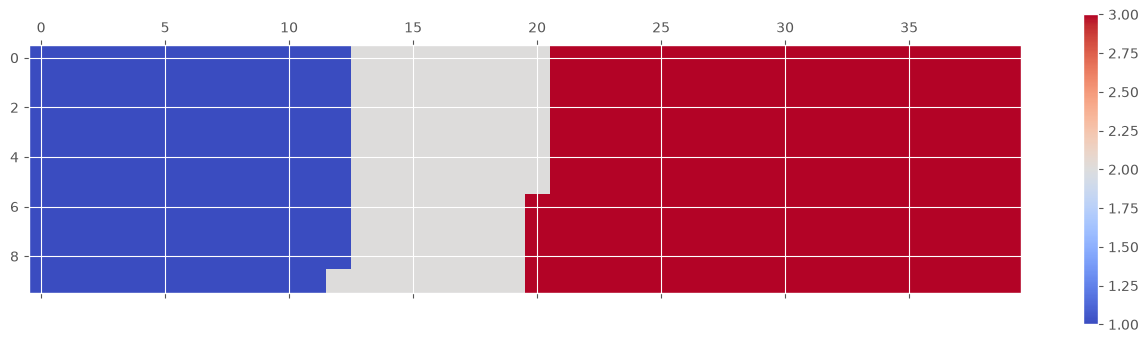

In [19]:
# instantiate a new figure object
# 最后，将华夫饼从矩阵转变成可视化的图：
fig = plt.figure()
# use matshow to display the waffle chart
colormap = plt.cm.coolwarm
plt.matshow(waffle_chart_DSN, cmap=colormap)
plt.colorbar(
plt.show()
# 只要跟着这些步骤去就可以了，不需要创新的代码：
# 下面的图像就是华夫饼图了。但是他们没有图例，还是会造成读图的困扰。

**Step 6.** Prettify the chart.


<Figure size 640x480 with 0 Axes>

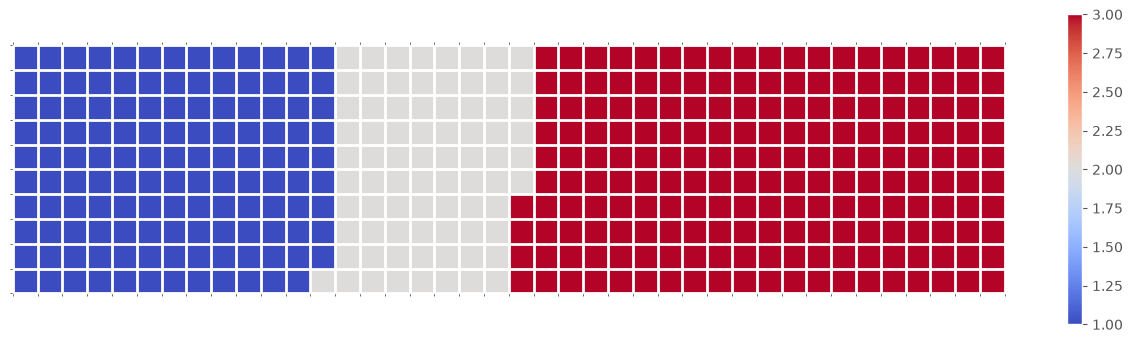

In [20]:
# instantiate a new figure object
# 我们将图片弄得更加美观一些吧！再画一遍图：
fig = plt.figure()
# use matshow to display the waffle chart
colormap = plt.cm.coolwarm
plt.matshow(waffle_chart_DSN, cmap=colormap)
plt.colorbar()
# get the axis
ax = plt.gca()
# set minor ticks
ax.set_xticks(np.arange(-.5, (width), 1), minor=True)
ax.set_yticks(np.arange(-.5, (height), 1), minor=True)
# add gridlines based on minor ticks
ax.grid(which='minor', color='w', linestyle='-', linewidth=2)
plt.xticks([])
plt.yticks([])
plt.show()
# 这个操作是将图片切成了小方块。比上图更好统计每个国家所占的比例。

**Step 7.** Create a legend and add it to chart.


<Figure size 640x480 with 0 Axes>

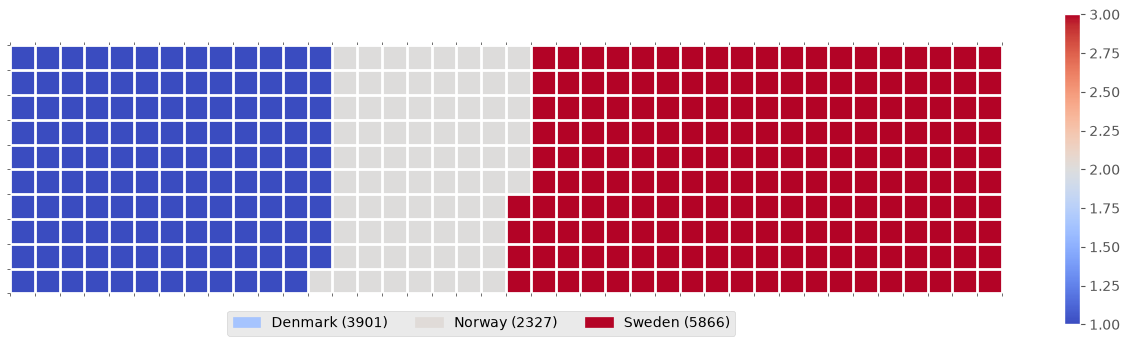

In [26]:
# instantiate a new figure object
fig = plt.figure()
# use matshow to display the waffle chart
colormap = plt.cm.coolwarm
plt.matshow(waffle_chart_DSN, cmap=colormap)
plt.colorbar()
# get the axis
ax = plt.gca()
# set minor ticks
ax.set_xticks(np.arange(-.5, (width), 1), minor=True)
ax.set_yticks(np.arange(-.5, (height), 1), minor=True)
# add gridlines based on minor ticks
ax.grid(which = 'minor', color = 'w', linestyle = '-', linewidth = 2)
plt.xticks([])
plt.yticks([])

# compute cumulative sum of individual categories to match color schemes between chart and legend
values_cumsum = np.cumsum(Canada_immigration_DSN['Total'])
total_values = values_cumsum.iloc[-1]
# create legend
legend_handles = [
    mpatches.Patch(
        color = colormap(float(cumsum)/total_values),
        label = f"{cat} ({total})"
    )
    for cat, total, cumsum in zip( Canada_immigration_DSN.index, Canada_immigration_DSN['Total'], values_cumsum )
]
# add legend to chart
ax = plt.gca()
# 隐藏四条边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
# 刻度的短线去掉，但刻度数字保留
ax.tick_params(axis='both', length=0)
plt.legend(handles = legend_handles,
           loc = 'lower center', 
           ncol = len( Canada_immigration_DSN.index.values ),
           bbox_to_anchor = (0., -0.2, 0.95, .1)
          )
plt.show()
# 最后这个步骤就是绘制完整的图片了。后面的练习应参考这个代码块：

And there you go! What a good looking *delicious* `waffle` chart, don't you think?


Now it would very inefficient to repeat these seven steps every time we wish to create a `waffle` chart. So let's combine all seven steps into one function called *create_waffle_chart*. This function would take the following parameters as input:

> 1.  **categories**: Unique categories or classes in dataframe.
> 2.  **values**: Values corresponding to categories or classes.
> 3.  **height**: Defined height of waffle chart.
> 4.  **width**: Defined width of waffle chart.
> 5.  **colormap**: Colormap class
> 6.  **value_sign**: In order to make our function more generalizable, we will add this parameter to address signs that could be associated with a value such as %, $, and so on. **value_sign** has a default value of empty string.


In [126]:
# 因为直接按照上面七个步骤绘制华夫饼图实在是太慢了。所以新建了一个函数，叫做 create_waffle_chart()，
# 以便以后调用，一步到位绘制出图：
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def create_waffle_chart(categories, values, height, width, colormap, value_sign=''):
    categories = list(categories)
    values = list(values)
    
    total_values = sum(values)
    category_proportions = [float(v) / total_values for v in values]
    total_num_tiles = width * height
    tiles_per_category = [round(p * total_num_tiles) for p in category_proportions]
    print('Total number of tiles:', total_num_tiles)
    for i, tiles in enumerate(tiles_per_category):
        print(categories[i], ':', tiles)
        
    waffle_chart = np.zeros((height, width))
    category_index = 0
    tile_index = 0
    for col in range(width):
        for row in range(height):
            tile_index += 1
            if tile_index > sum(tiles_per_category[:category_index]):
                category_index += 1
            waffle_chart[row, col] = category_index
            
    # ========== 严格复刻lab课件代码！！ ==========
    fig = plt.figure()
    plt.matshow(waffle_chart, cmap=colormap)
    plt.colorbar()
    ax = plt.gca()
    
    # 次刻度，用来画分割白线
    ax.set_xticks(np.arange(-0.5, width, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, height, 1), minor=True)
    # 白线粗一点！课件 linewidth=2
    ax.grid(which='minor', color='white', linestyle='-', linewidth=2)
    
    # 【重点！删掉主刻度！课件这里清空刻度】
    ax.set_xticks([])
    ax.set_yticks([])
    
    # 隐藏四周边框
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # 图例部分
    values_cumsum = np.cumsum(values)
    legend_handles = []
    for i, cat in enumerate(categories):
        label_str = f"{cat} ({values[i]})"
        color_val = colormap(values_cumsum[i]/total_values)
        legend_handles.append(mpatches.Patch(color=color_val, label=label_str))
        
    plt.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=len(categories),
        bbox_to_anchor=(0, -0.2, 0.95, .1)
    )
    plt.show()

Now to create a `waffle` chart, all we have to do is call the function `create_waffle_chart`. Let's define the input parameters:


In [127]:
width = 40
height = 10
categories = Canada_immigration_DSN.index.tolist()
values = Canada_immigration_DSN['Total'].tolist()

And now let's call our function to create a `waffle` chart.


Total number of tiles: 400
Denmark : 129
Norway : 77
Sweden : 194


<Figure size 640x480 with 0 Axes>

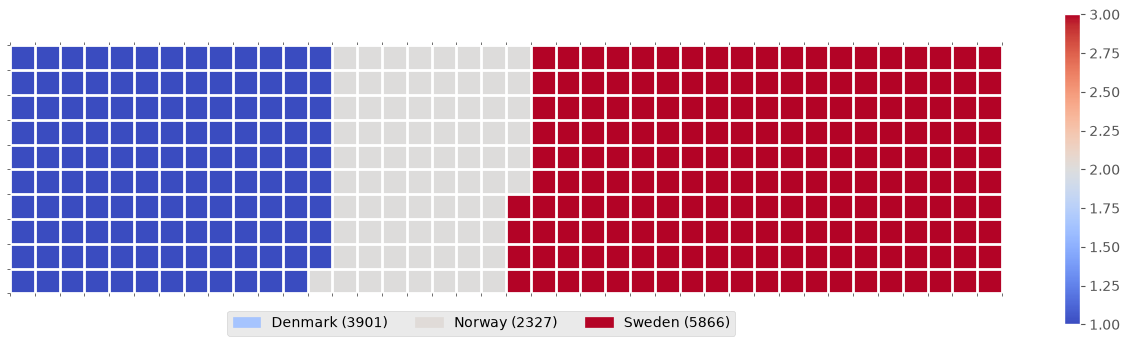

In [129]:
create_waffle_chart(categories, values, height, width, colormap)

There seems to be a new Python package for generating `waffle charts` called [PyWaffle](https://github.com/ligyxy/PyWaffle), <br><br>Let's create the same waffle chart with **pywaffle** now


In [30]:
#install pywaffle
# 似乎有一个新的Python包用于生成华夫饼图，名为PyWaffle。
# 现在让我们用pywaffle创建相同的华夫饼图。
!pip install pywaffle
# 从输出结果可以看出，PyWaffle已经成功安装。

Defaulting to user installation because normal site-packages is not writeable


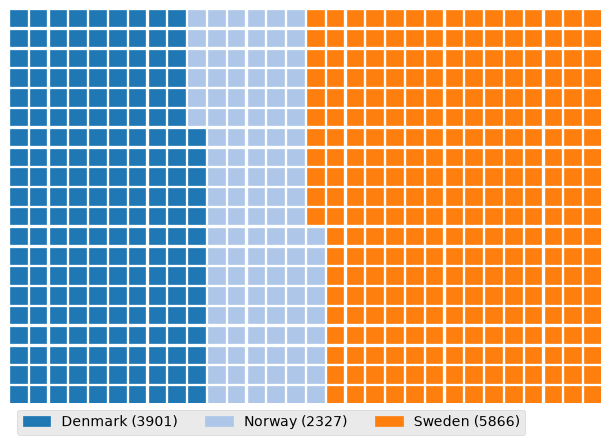

In [132]:
#import Waffle from pywaffle
from pywaffle import Waffle
#Set up the Waffle chart figure
# 设置画华夫饼图的各个参数：
fig = plt.figure(FigureClass = Waffle,
                 rows = 20, columns = 30, #pass the number of rows and columns for the waffle 
                 values = Canada_immigration_DSN['Total'], #pass the data to be used for display
                 cmap_name = 'tab20', #color scheme
                 legend = {'labels': [f"{k} ({v})" for k, v in zip(Canada_immigration_DSN.index.values,Canada_immigration_DSN.Total)],
                            'loc': 'lower left', 'bbox_to_anchor':(0,-0.1),'ncol': 3}
                 #notice the use of list comprehension for creating labels 
                 #from index and total of the dataset
                )
#Display the waffle chart
# 一步到位，直接画图：
plt.show()

**Question:** Create a Waffle chart to dispaly the proportiona of China and Inida total immigrant contribution.


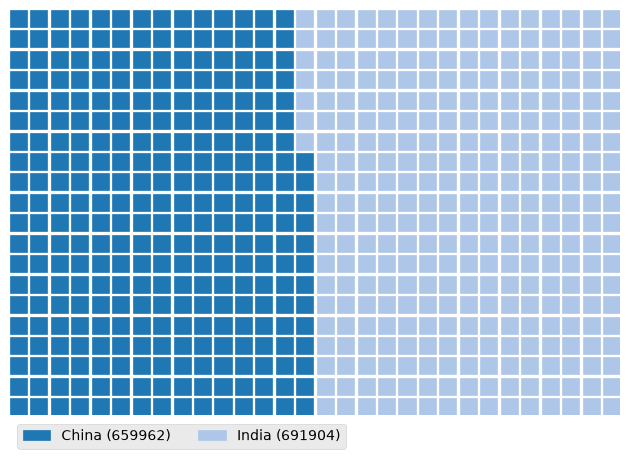

In [133]:
# 创建一个华夫饼图，以显示中国和印度总移民贡献的比例。
# 对数据集 Canada_immigration 使用 loc提取功能，选择国家名为 China和 India：
# 将新变量命名为 Canada_immigration_CI:
Canada_immigration_CI = Canada_immigration.loc[['China', 'India'], :]
# 参考上面的代码，抄下来并修改参数：
#import Waffle from pywaffle
from pywaffle import Waffle
fig = plt.figure( FigureClass = Waffle,
                 rows = 20, columns = 30, #pass the number of rows and columns for the waffle 
                 values = Canada_immigration_CI['Total'], #pass the data to be used for display
                 cmap_name = 'tab20', #color scheme
                 legend = {'labels': [f"{k} ({v})" for k, v in zip(Canada_immigration_CI.index.values, Canada_immigration_CI.Total)],
                            'loc': 'lower left', 'bbox_to_anchor':(0,-0.1),'ncol': 3}
                 #notice the use of list comprehension for creating labels 
                 #from index and total of the dataset
                )
#Display the waffle chart
# 一步到位，直接画图：
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
#hint
#create dataframe
data_CI = .............
#Set up the Waffle chart figure

fig = plt.figure(FigureClass = ............,
                     rows = ........, columns =....., #pass the number of rows and columns for the waffle 
                     values = ........., #pass the data to be used for display
                     cmap_name = 'tab20', #color scheme
                     legend = {'labels':[.......],
                                'loc': ........., 'bbox_to_anchor':(....),'ncol': 2}
                     #notice the use of list comprehension for creating labels 
                     #from index and total of the dataset
                    )

#Display the waffle chart
plt.show()
```


# Word Clouds <a id="4"></a>

`Word` clouds (also known as text clouds or tag clouds) work in a simple way: the more a specific word appears in a source of textual data (such as a speech, blog post, or database), the bigger and bolder it appears in the word cloud.


Luckily, a Python package already exists in Python for generating `word` clouds. The package, called `word_cloud` was developed by **Andreas Mueller**. You can learn more about the package by following this [link](https://github.com/amueller/word_cloud/).

Let's use this package to learn how to generate a word cloud for a given text document.


First, let's install the package.


In [140]:
#import package and its set of stopwords
# 在绘制词云图之前，让我们先安装包：
from wordcloud import WordCloud, STOPWORDS
print ('Wordcloud imported!')
# 从输出结果可见，已经成功安装！

Wordcloud imported!


`Word` clouds are commonly used to perform high-level analysis and visualization of text data. Accordinly, let's digress from the immigration dataset and work with an example that involves analyzing text data. Let's try to analyze a short novel written by **Lewis Carroll** titled *Alice's Adventures in Wonderland*. Let's go ahead and download a *.txt* file of the novel.


In [141]:
import urllib
# # open the file and read it into a variable alice_novel
alice_novel = urllib.request.urlopen('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/alice_novel.txt').read().decode("utf-8")

Next, let's use the stopwords that we imported from `word_cloud`. We use the function *set* to remove any redundant stopwords.


In [142]:
stopwords = set(STOPWORDS)

Create a word cloud object and generate a word cloud. For simplicity, let's generate a word cloud using only the first 2000 words in the novel.


In [143]:
#if you get attribute error while generating worldcloud, upgrade Pillow and numpy using below code
#%pip install --upgrade Pillow 
#%pip install --upgrade numpy

In [144]:
# instantiate a word cloud object
alice_wc = WordCloud()
# generate the word cloud
alice_wc.generate(alice_novel)

Awesome! Now that the `word` cloud is created, let's visualize it.


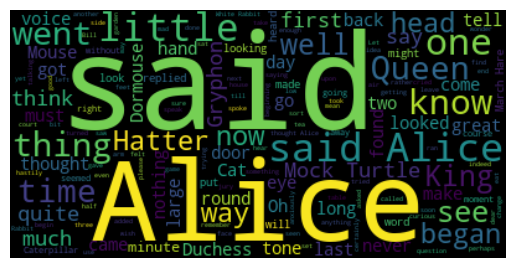

In [145]:
# display the word cloud、
# 前面都不需要调整任何代码，因为是示例，这里直接运行就可以看见词云图了：
plt.imshow(alice_wc, interpolation='bilinear')
plt.axis('off')
plt.show()

Interesting! So in the first 2000 words in the novel, the most common words are **Alice**, **said**, **little**, **Queen**, and so on. Let's resize the cloud so that we can see the less frequent words a little better.


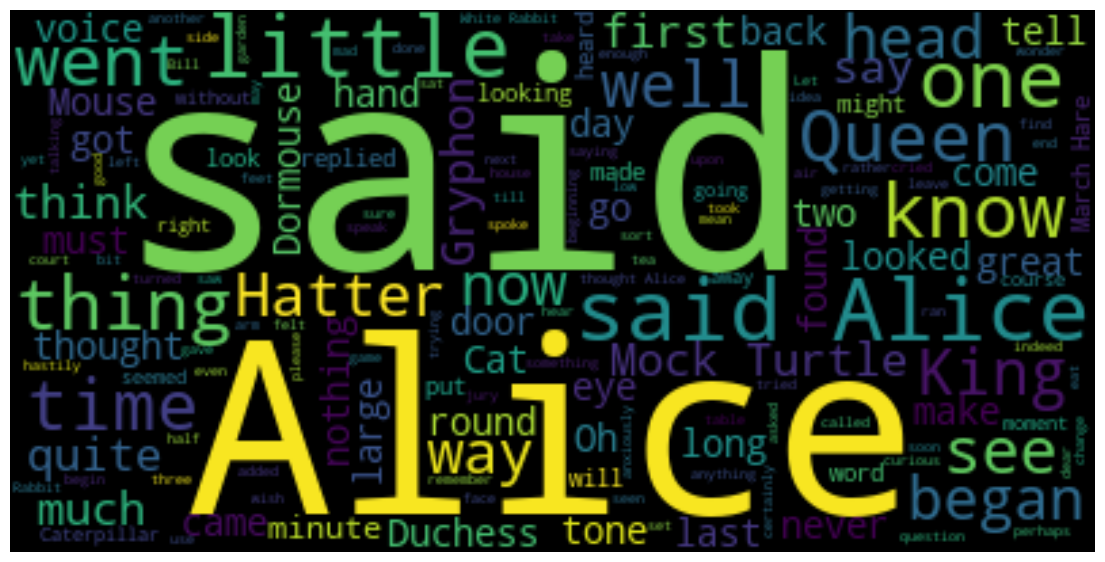

In [146]:
#因此，在小说的前2000个单词中，最常见的词是Alice、said、litle、Queen等。
# 让我们调整一下云图，以便更好地看到较少出现的词汇。
%matplotlib inline
# 调整图片尺寸，大幅扩大，以更好地看清楚很小的文字：
fig = plt.figure(figsize=(14, 18))
# display the cloud
# 然后依然是作图代码：
plt.imshow(alice_wc, interpolation='bilinear')
plt.axis('off')
plt.show()
# 从下面的图可以看出，这张图被大幅度的扩大了，可以成功看见缩小的文字。

Much better! However, **said** isn't really an informative word. So let's add it to our stopwords and re-generate the cloud.


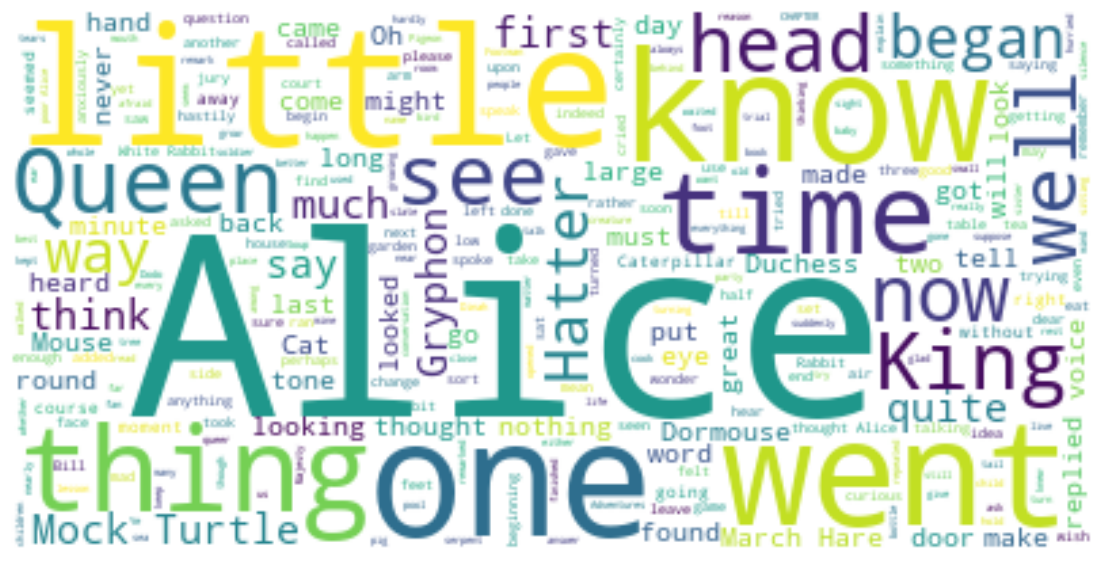

In [147]:
#然而，said并不是一个真正具有信息量的词。因此，让我们将其添加到停用词列表中，并重新生成词云。
stopwords.add('said') # add the words said to stopwords
# 重点：重新新建对象，这次把stopwords放进去，补上background_color（很多环境缺这个就空白）：
alice_wc = WordCloud(background_color='white', max_words=2000, stopwords=stopwords)
alice_wc.generate(alice_novel)
# display the cloud
# 绘制图像
fig = plt.figure(figsize=(14, 18))
plt.imshow(alice_wc, interpolation='bilinear')
plt.axis('off')
plt.show()

Excellent! This looks really interesting! Another cool thing you can implement with the `word_cloud` package is superimposing the words onto a mask of any shape. Let's use a mask of Alice and her rabbit. We already created the mask for you, so let's go ahead and download it and call it *alice_mask.png*.


In [149]:
#save mask to alice_mask
alice_mask = np.array(Image.open(urllib.request.urlopen('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%204/images/alice_mask.png')))

Let's take a look at how the mask looks like.


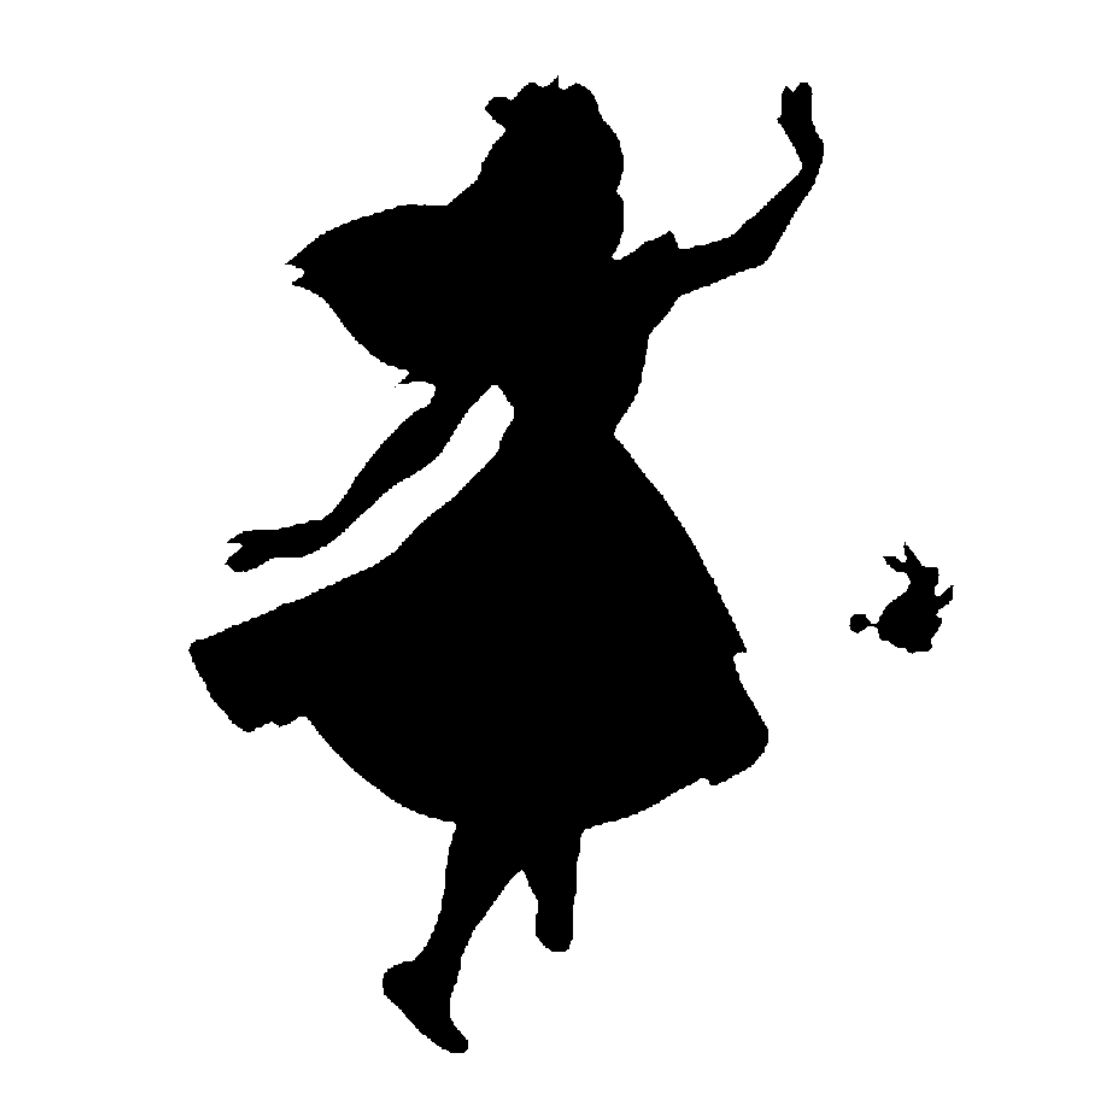

In [150]:
# 用word_cloud包，另一个很酷的功能是将文字叠加到任意形状的掩膜上。
# 让我们使用爱丽丝和她兔子的掩膜。
# 我们已经为您创建了掩膜，现在请将其下载并命名为alice_mask.png。
fig = plt.figure(figsize=(14, 18))
plt.imshow(alice_mask, cmap=plt.cm.gray, interpolation='bilinear')
plt.axis('off')
plt.show()
# 下面的图就是绘制出来的掩膜。要加到图片里面的话，应该修改透明度。

Shaping the `word` cloud according to the mask is straightforward using `word_cloud` package. For simplicity, we will continue using the first 2000 words in the novel.


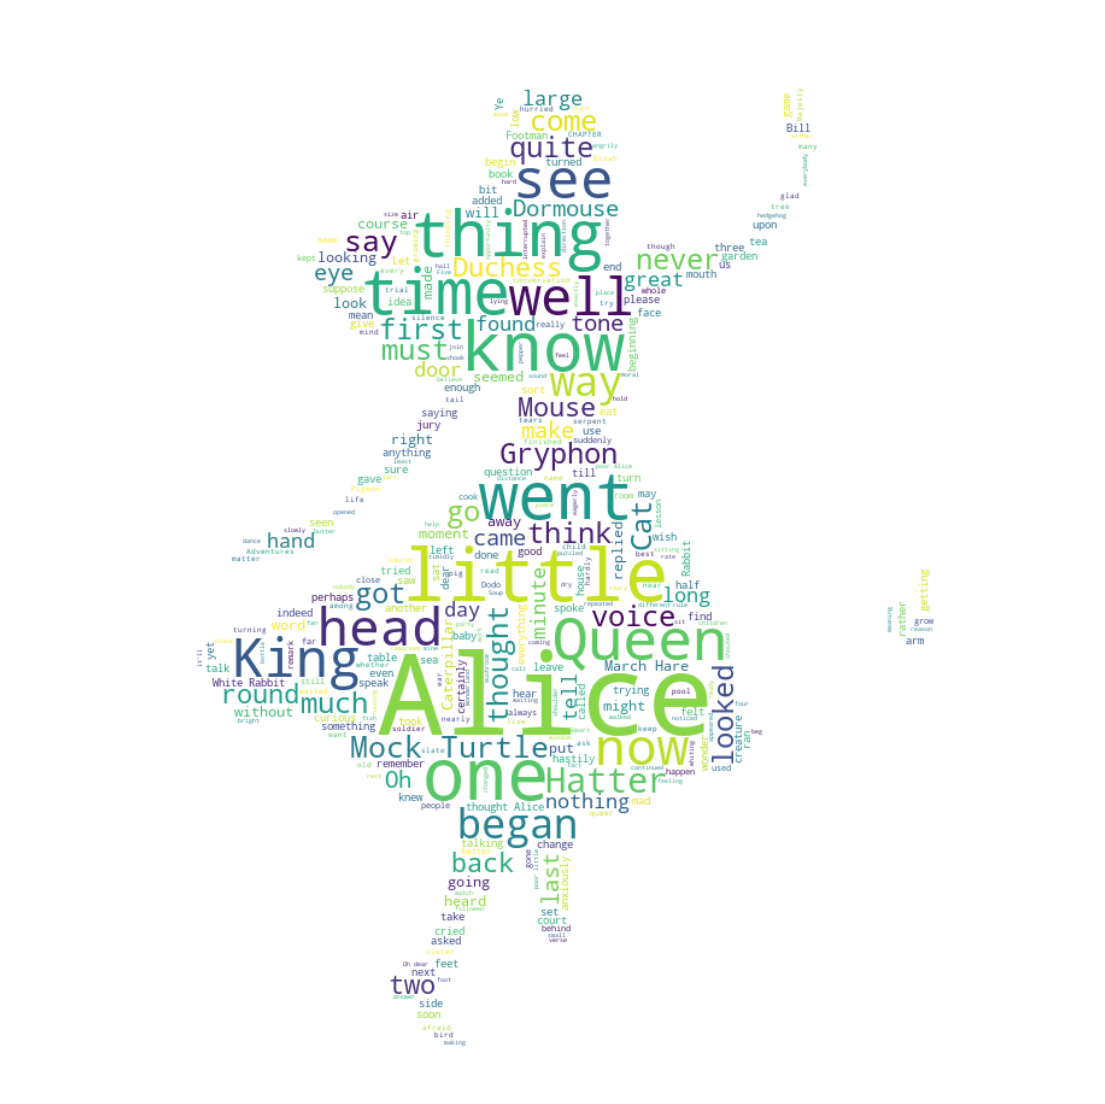

In [152]:
# 根据掩码生成词云使用word_cloud包非常直接。
# 为了简化，我们将继续使用小说中的前2000个单词。
# instantiate a word cloud object
alice_wc = WordCloud(background_color='white', max_words=2000, mask=alice_mask, stopwords=stopwords)
# generate the word cloud
# 生成词云
alice_wc.generate(alice_novel)
# 展示词云
# display the word cloud
fig = plt.figure(figsize=(14, 18))
plt.imshow(alice_wc, interpolation='bilinear')
plt.axis('off')
plt.show()
# 这次，词云都被填充到掩膜里去了：

Really impressive!


Unfortunately, our immigration data does not have any text data, but where there is a will there is a way. Let's generate sample text data from our immigration dataset, say text data of 90 words.


Let's recall how our data looks like.


In [154]:
# 让我们从我们的移民数据集中生成一些示例文本数据，例如90个单词的文本数据。
# 让我们回顾一下我们的数据是什么样子的。
Canada_immigration.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


And what was the total immigration from 1980 to 2013?


In [156]:
# 然后，从1980-2013年移民去加拿大的总人数是多少？
# 对Total这一列使用sum()函数，求和：
# 将新的变量命名为 total_immigration:
total_immigration = Canada_immigration['Total'].sum()
total_immigration

np.int64(6409153)

Using countries with single-word names, let's duplicate each country's name based on how much they contribute to the total immigration.


In [157]:
# 对于单字名称的国家，我们将根据其对总移民贡献的程度n重复每个国家的名字。
max_words = 90
word_string = ''
for country in Canada_immigration.index.values:
     # check if country's name is a single-word name
    if country.count(" ") == 0:
        repeat_num_times = int(Canada_immigration.loc[country, 'Total'] / total_immigration * max_words)
        word_string = word_string + ((country + ' ') * repeat_num_times)
# display the generated text
word_string

'China China China China China China China China China Colombia Egypt France Guyana Haiti India India India India India India India India India Jamaica Lebanon Morocco Pakistan Pakistan Pakistan Philippines Philippines Philippines Philippines Philippines Philippines Philippines Poland Portugal Romania '

We are not dealing with any stopwords here, so there is no need to pass them when creating the word cloud.


In [158]:
# 我们这里不处理任何停用词，因此在创建词云时无需过滤这些词。
# create the word cloud
# 创建词云！
wordcloud = WordCloud(background_color='white').generate(word_string)
print('Word cloud created!')

Word cloud created!


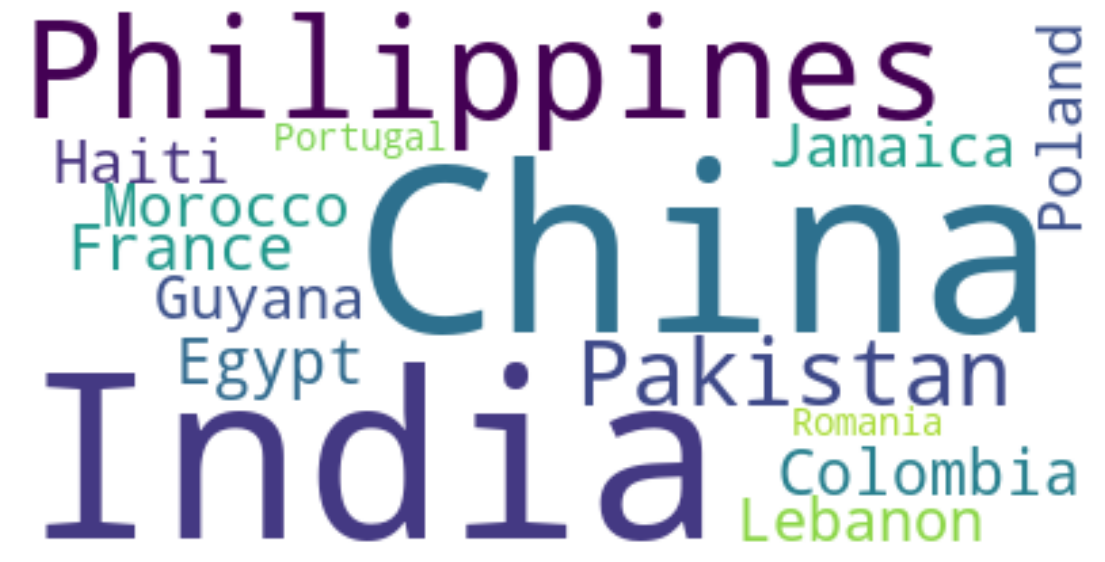

In [159]:
# display the cloud
# 出图！
plt.figure(figsize=(14, 18))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

According to the above word cloud, it looks like the majority of the people who immigrated came from one of 15 countries that are displayed by the word cloud. One cool visual that you could build, is perhaps using the map of Canada and a mask and superimposing the word cloud on top of the map of Canada. That would be an interesting visual to build!


# Plotting with Seaborn <a id="5"></a>

> Seaborn is a Python visualization library based on matplotlib. It provides a high-level interface for drawing attractive statistical graphics. You can learn more about *seaborn* by following this [link](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) and more about *seaborn* regression plots by following this [link](http://seaborn.pydata.org/generated/seaborn.regplot.html?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).


In lab *Pie Charts, Box Plots, Scatter Plots, and Bubble Plots*, we learned how to create a scatter plot and then fit a regression line. It took \~20 lines of code to create the scatter plot along with the regression fit. In this final section, we will explore *seaborn* and see how efficient it is to create regression lines and fits using this library!


### Categorical Plots
In our data 'df_can', let's find out how many continents are mentioned


In [160]:
# 去查找出 Canada_immigration 数据集里面有多少个洲被提及：
Canada_immigration['Continent'].unique()
# 结果是6个：

<ArrowStringArray>
[                           'Asia',                          'Europe',
                          'Africa',                         'Oceania',
 'Latin America and the Caribbean',                'Northern America']
Length: 6, dtype: str

### countplot
**A count plot can be thought of as a histogram across a categorical, instead of quantitative, variable.**
Let's find the count of Continents in the data 'df_can' using countplot on 'Continent'


<Figure size 1200x600 with 0 Axes>

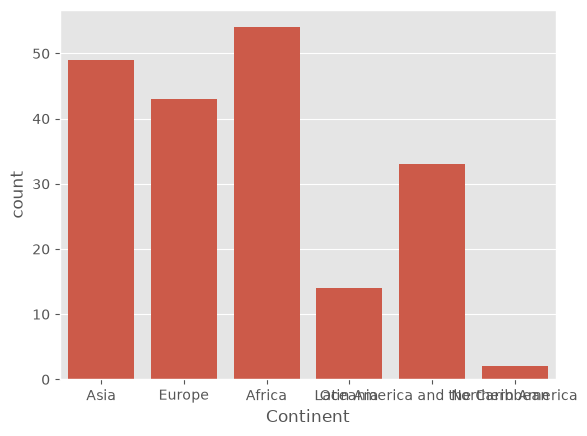

<Figure size 1200x600 with 0 Axes>

In [168]:
# 计数图可以被视为一个横跨分类变量而非定量变量的直方图。
# 让我们使用countplot，对数据中的 Continent列进行统计，以找出各大洲的数量。
sns.countplot(x ='Continent', data = Canada_immigration)
plt.figure(figsize=(12, 6))

The labels on the x-axis doesnot look as expected.<br>Let's try to replace the 'Latin America and the Caribbean' with and "L-America", 'Northern America' with "N-America", <br>and change the figure size and then display the plot again


In [170]:
# 因为大洲的名称过长了，导致堆叠，所以调整了名字，和图幅：
Canada_immigration1 = Canada_immigration.replace('Latin America and the Caribbean', 'L-America')
Canada_immigration1 = Canada_immigration1.replace('Northern America', 'N-America')

<Axes: xlabel='Continent', ylabel='count'>

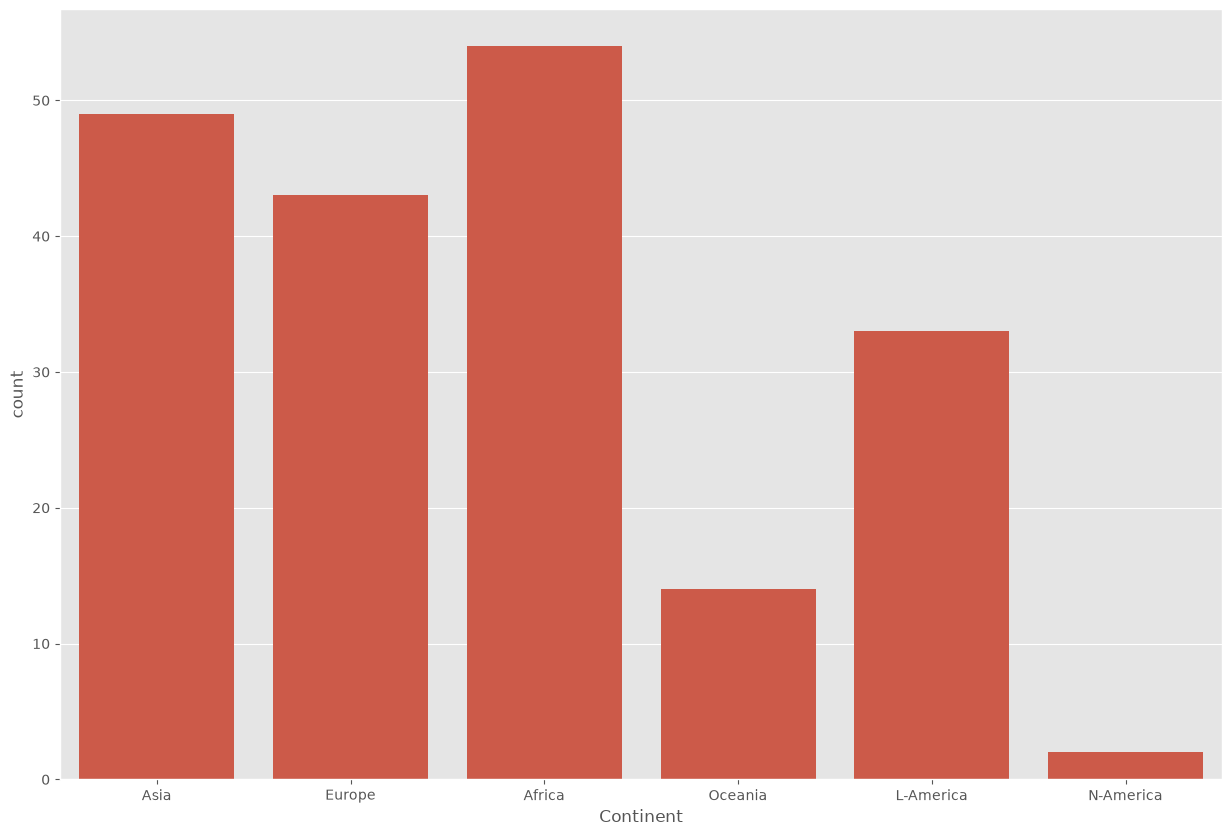

In [171]:
plt.figure(figsize=(15, 10))
sns.countplot(x='Continent', data=Canada_immigration1)
# 从下面的输出结果来看，这下就漂亮很多了：

Much better!


### Barplot
**This plot will perform the Groupby on a categorical varaible and plot aggregated values, with confidence intervals**.<br> Let's plot the total immigrants Continent-wise


<Axes: xlabel='Continent', ylabel='Total'>

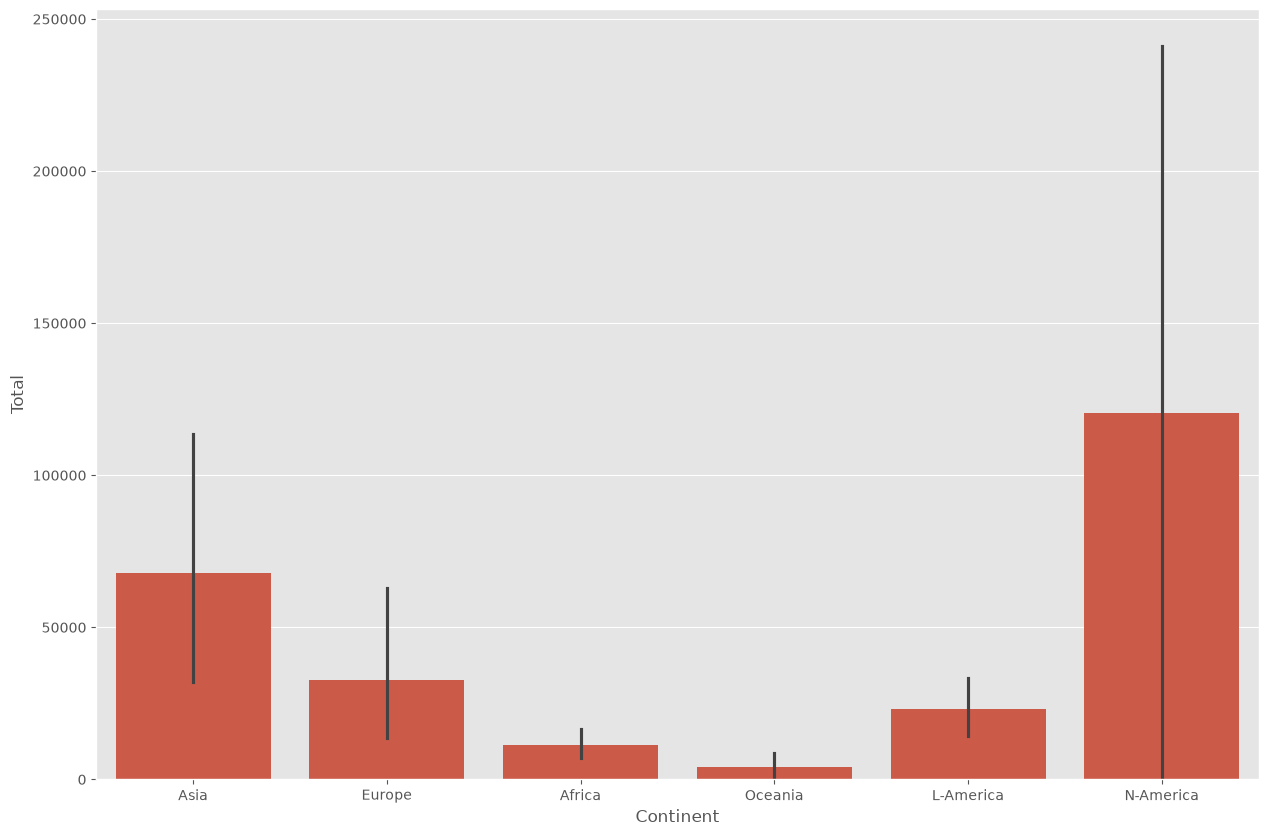

In [174]:
# 绘制条形图：
# 此图表将对分类变量执行分组操作，并绘制汇总值及其置信区间。
# 让我们按大陆划分绘制总移民人数。
plt.figure( figsize=(15, 10))
sns.barplot( x='Continent', y='Total', data=Canada_immigration1)

You can verify the values by performing the groupby on the Total and Continent for mean()


In [175]:
# 你可以通过对Total和 Continent进行 groupby() 操作，来验证 mean()的值
Canada_immigration2 = Canada_immigration1.groupby('Continent')['Total'].mean()
Canada_immigration2

Continent
Africa        11462.000000
Asia          67710.081633
Europe        32812.720930
L-America     23186.303030
N-America    120571.000000
Oceania        3941.000000
Name: Total, dtype: float64

Create a new dataframe that stores that total number of landed immigrants to Canada per year from 1980 to 2013.


In [176]:
# 按年份求和，得到每年移民总数
years = list(map(str, range(1980, 2014)))
df_year_total = Canada_immigration[years].sum(axis=0)
df_year_total = df_year_total.reset_index()
df_year_total.columns = ['Year', 'Total_Immigration']
df_year_total

,Year,Total_Immigration
0,1980,99137
1,1981,110563
2,1982,104271
3,1983,75550
4,1984,73417
5,1985,69978
6,1986,86048
7,1987,134771
8,1988,139306
9,1989,164432


# Regression Plot <a id="6"></a>
With *seaborn*, generating a regression plot is as simple as calling the **regplot** function.


In [177]:
# 使用seaborn，生成回归图就像调用regplot函数一样简单。
years = list(map(str, range(1980, 2014)))
# we can use the sum() method to get the total population per year
Canada_immigration_tot = pd.DataFrame(Canada_immigration[years].sum(axis=0))

# change the years to type float (useful for regression later on)
Canada_immigration_tot.index = map(float, Canada_immigration_tot.index)

# reset the index to put in back in as a column in the df_tot dataframe
Canada_immigration_tot.reset_index(inplace=True)

# rename columns
Canada_immigration_tot.columns = ['year', 'total']

# view the final dataframe
Canada_immigration_tot.head()

,year,total
0,1980.0,99137
1,1981.0,110563
2,1982.0,104271
3,1983.0,75550
4,1984.0,73417


<Axes: xlabel='year', ylabel='total'>

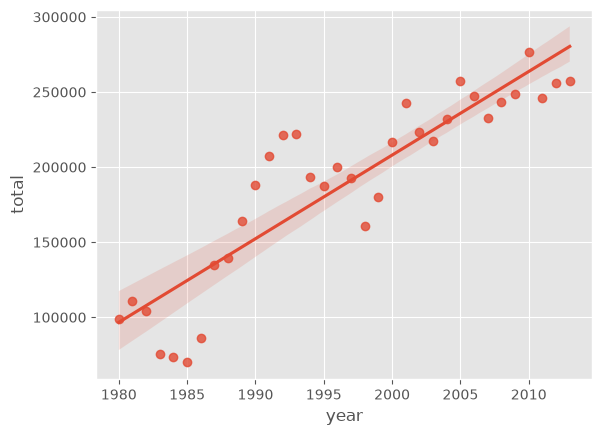

In [178]:
#seaborn is already imported at the start of this lab
sns.regplot(x='year', y='total', data=Canada_immigration_tot)

This is not magic; it is *seaborn*! You can also customize the color of the scatter plot and regression line. Let's change the color to green.


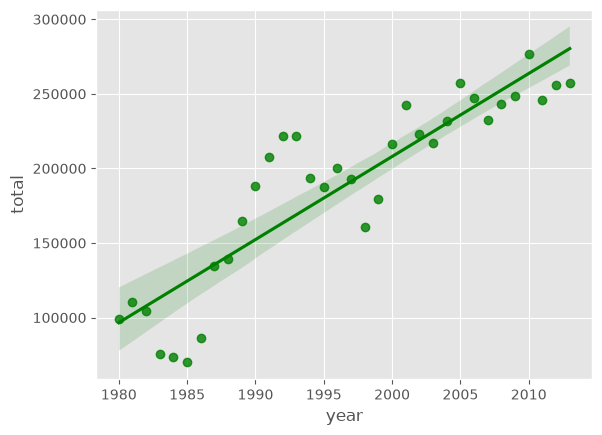

In [180]:
# 如果不喜欢原图的红色，可以改变图的颜色，比如说改成绿色：
sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green')
plt.show()

You can always customize the marker shape, so instead of circular markers, let's use `+`.


Amazing! A complete scatter plot with a regression fit with 5 lines of code only. Isn't this really amazing?


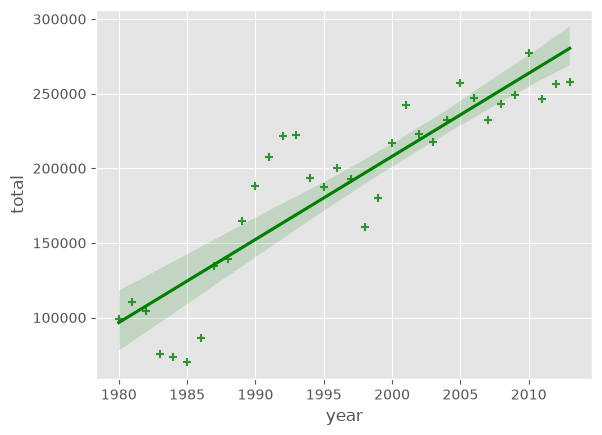

In [181]:
# 此外，我们还可以修改每个点的样子。
# 将圆点修改成十字架也是可以的：
ax = sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green', marker='+')
plt.show()

Let's blow up the plot a little so that it is more appealing to the sight.


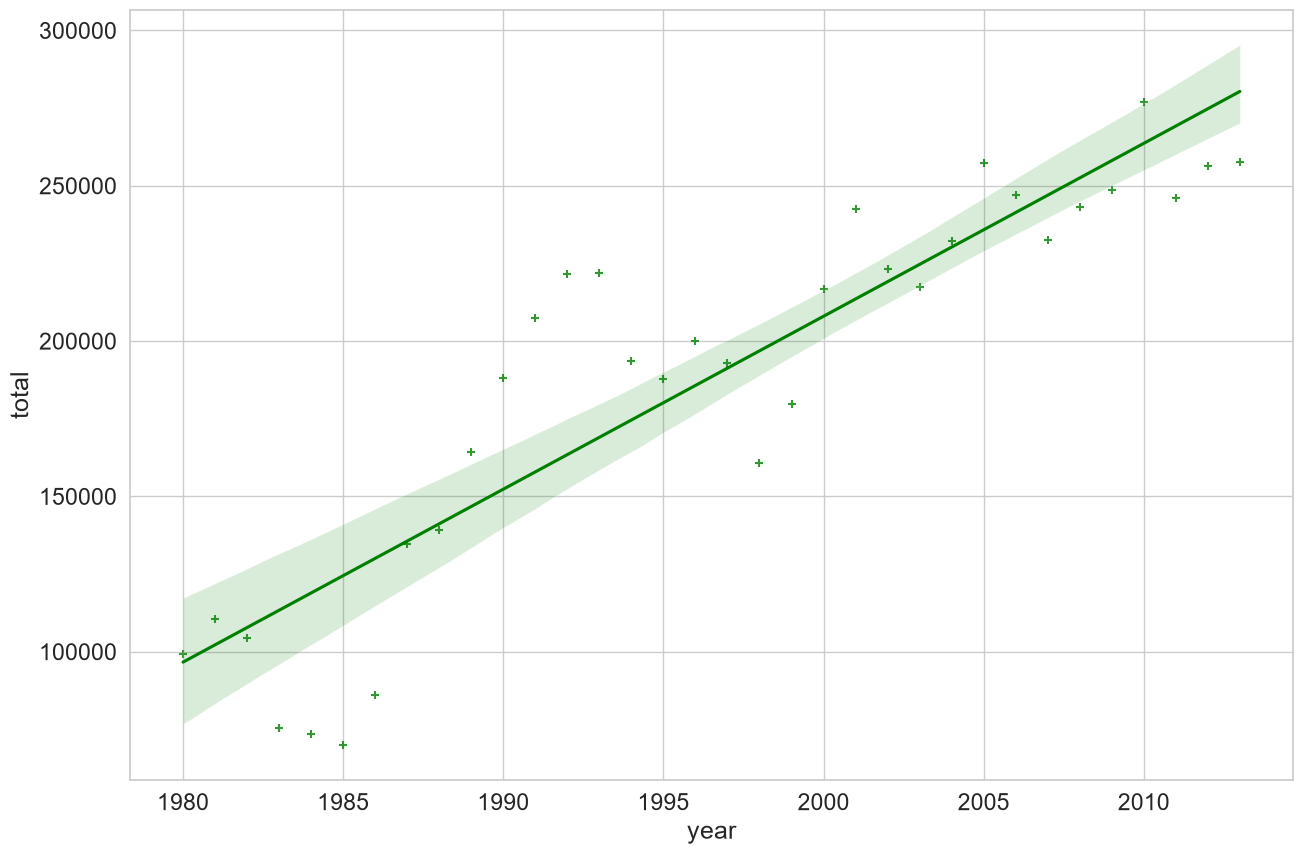

In [187]:
# 这里只是扩大了图幅，没有做其他实质性的改动。
plt.figure(figsize=(15, 10))
sns.regplot(x='year', y='total', data = Canada_immigration_tot, color='green', marker='+')
plt.show()

And let's increase the size of markers so they match the new size of the figure, and add a title and x- and y-labels.


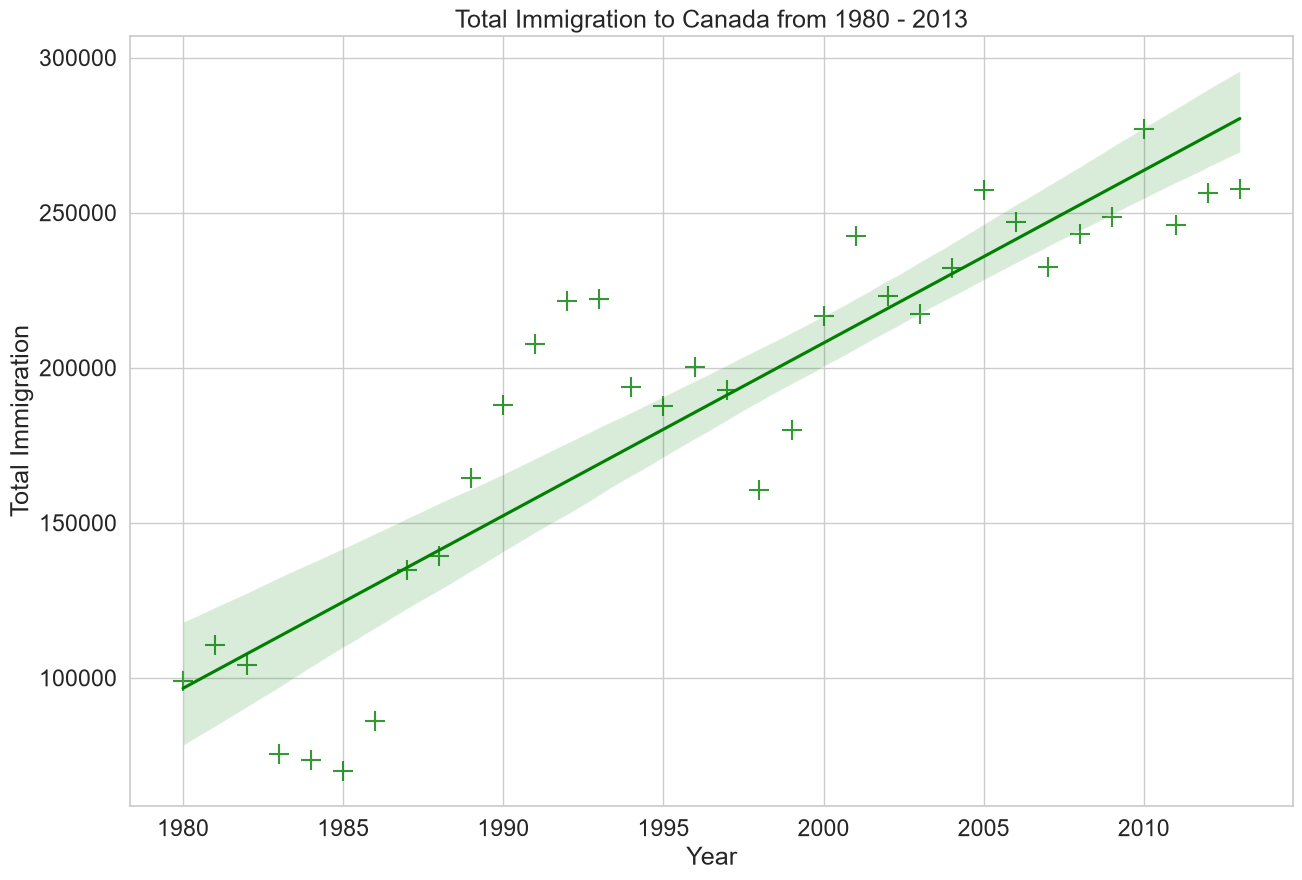

In [188]:
# 最后，为图片加上标题、行标题和列标题：
plt.figure(figsize=(15, 10))
ax = sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green', marker='+', scatter_kws={'s': 200})
ax.set(xlabel='Year', ylabel='Total Immigration') # add x- and y-labels
ax.set_title('Total Immigration to Canada from 1980 - 2013') # add title
plt.show()
# 最终的完美图像就是下面这样的：

And finally increase the font size of the tickmark labels, the title, and the x- and y-labels so they don't feel left out!


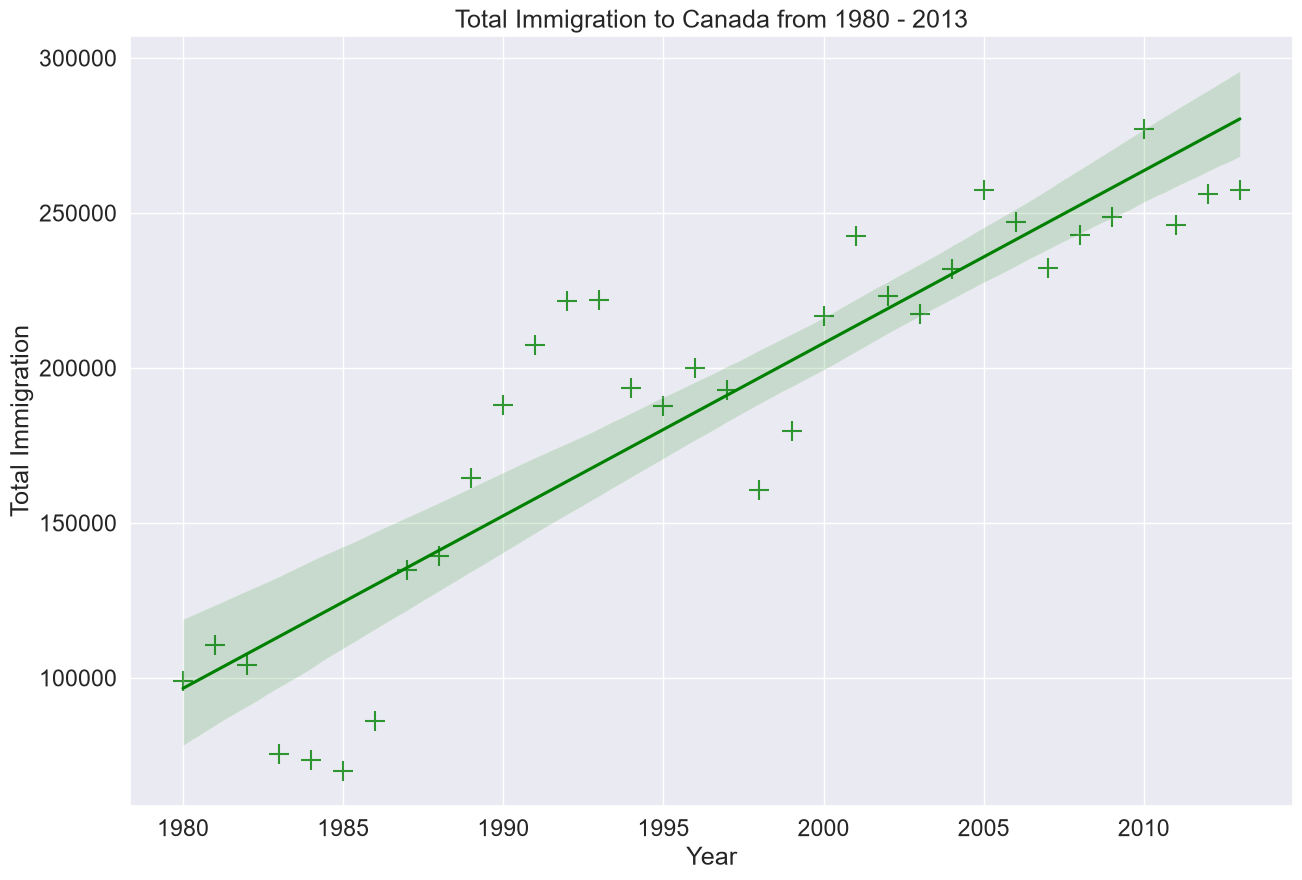

In [189]:
# 最后，增加刻度标签、标题以及x轴和y轴标签的字体大小，以免它们被忽略!
plt.figure(figsize=(15, 10))
sns.set(font_scale=1.5)
ax = sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green', marker='+', scatter_kws={'s': 200})
ax.set(xlabel='Year', ylabel='Total Immigration')
ax.set_title('Total Immigration to Canada from 1980 - 2013')
plt.show()

If you are not a big fan of the purple background, you can easily change the style to a white plain background.


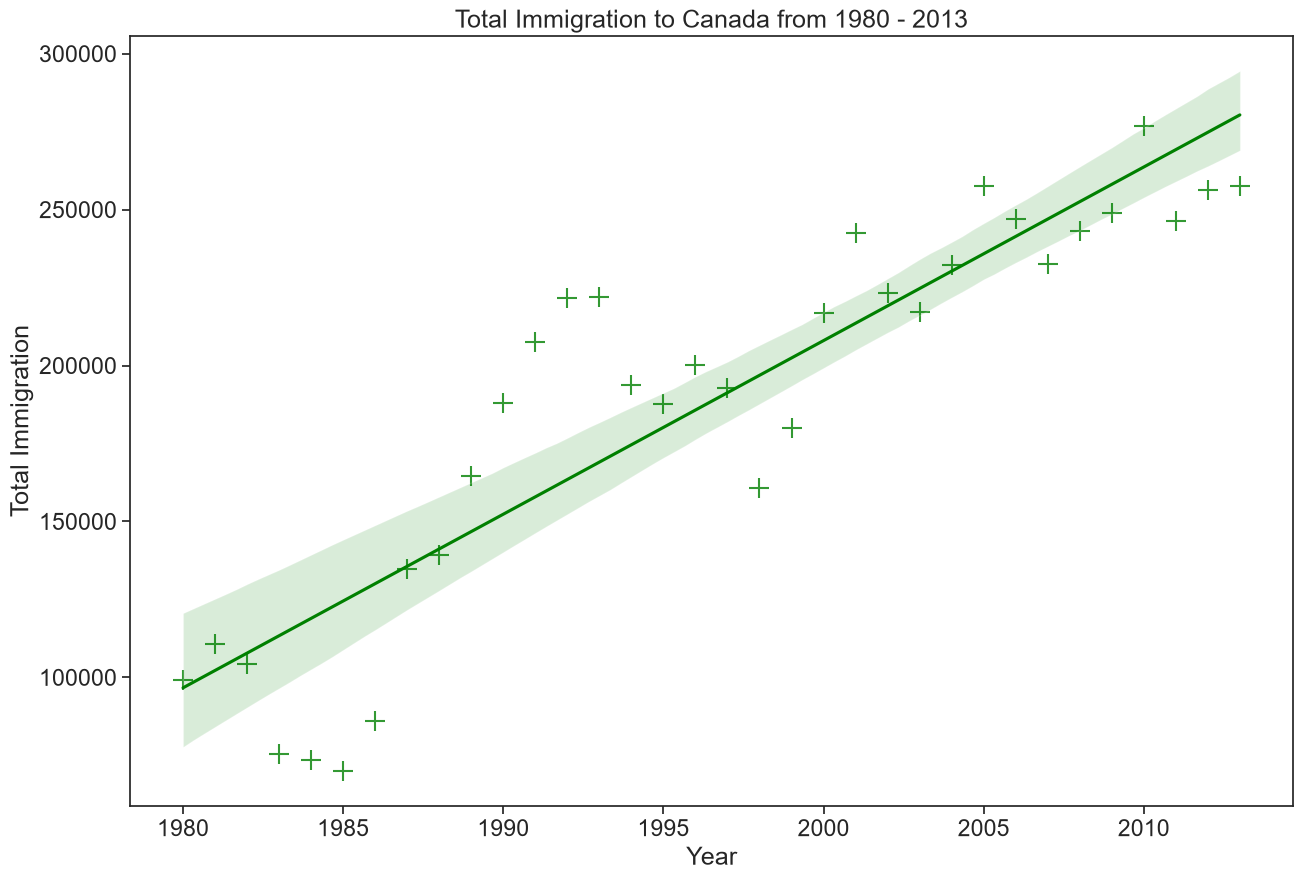

In [190]:
# 如果不喜欢紫色的背景，可以将它们换掉：
plt.figure(figsize=(15, 10))
sns.set(font_scale=1.5)
sns.set_style('ticks')  # change background to white background
ax = sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green', marker='+', scatter_kws={'s': 200})
ax.set(xlabel='Year', ylabel='Total Immigration')
ax.set_title('Total Immigration to Canada from 1980 - 2013')
plt.show()

Or to a white background with gridlines.


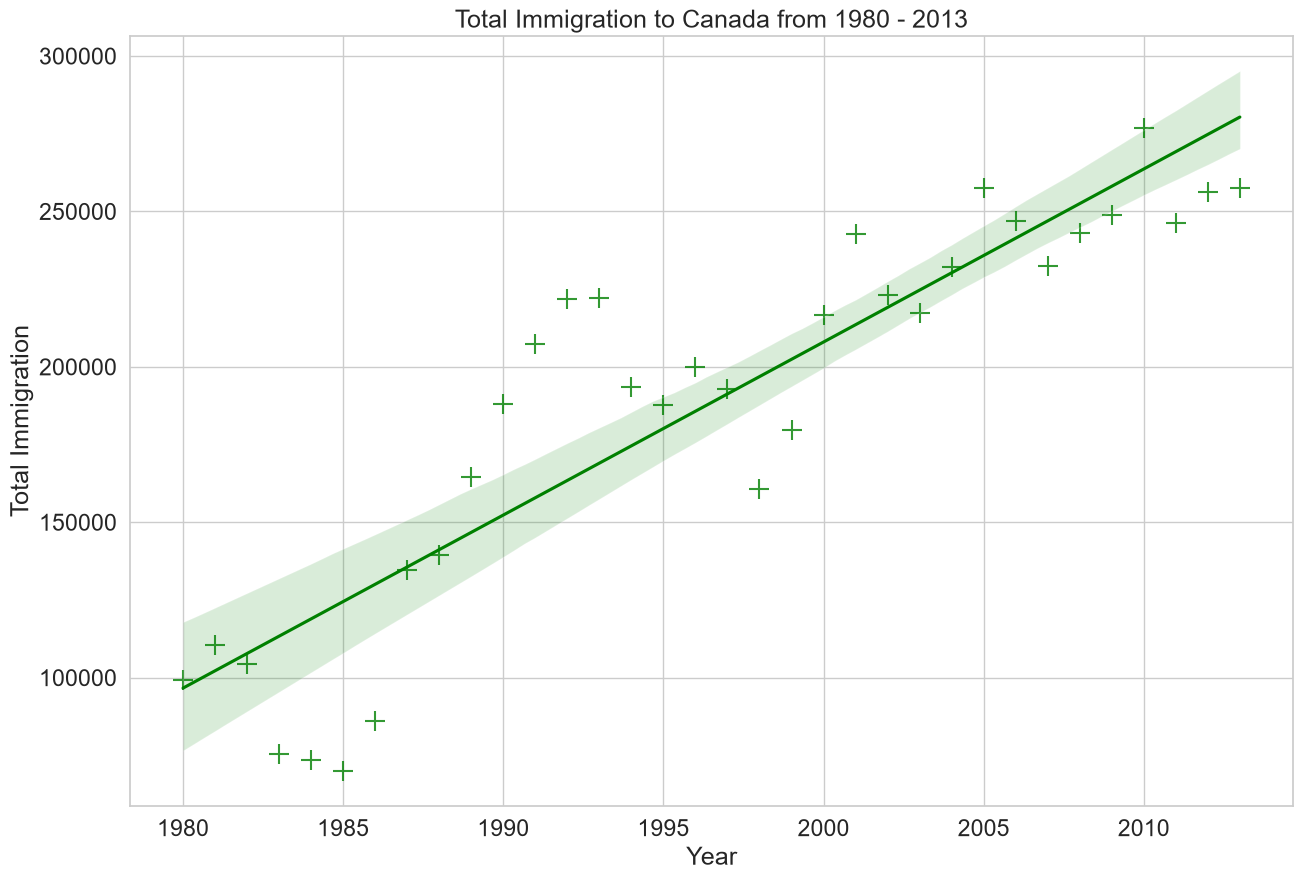

In [191]:
# 白色底边框加上网格线也是很好的：
plt.figure(figsize=(15, 10))
sns.set(font_scale=1.5)
sns.set_style('whitegrid')
ax = sns.regplot(x='year', y='total', data=Canada_immigration_tot, color='green', marker='+', scatter_kws={'s': 200})
ax.set(xlabel='Year', ylabel='Total Immigration')
ax.set_title('Total Immigration to Canada from 1980 - 2013')
plt.show()

**Question**: Use seaborn to create a scatter plot with a regression line to visualize the total immigration from Denmark, Sweden, and Norway to Canada from 1980 to 2013.


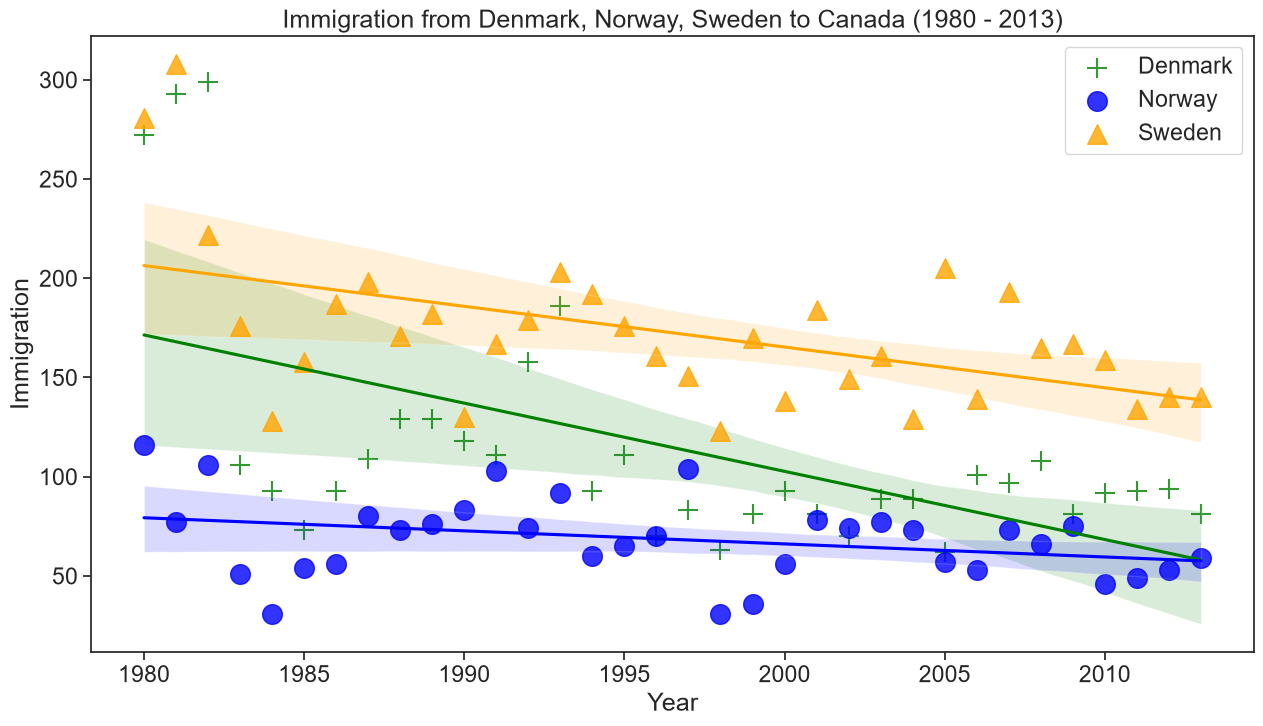

In [198]:
### type your answer here
# 提取三国数据
Canada_immigration_DNS = Canada_immigration.loc[['Denmark', 'Norway', 'Sweden'], years]
# 转置：行=年份，列=三个国家
Canada_immigration_DNS_transposed = Canada_immigration_DNS.transpose()
# 把年份索引变成普通列，列名叫 Year
Canada_immigration_DNS_transposed = Canada_immigration_DNS_transposed.reset_index()
Canada_immigration_DNS_transposed.rename(columns={"index":"Year"}, inplace=True)
Canada_immigration_DNS_transposed["Year"] = Canada_immigration_DNS_transposed["Year"].astype(int)
# 参考上面的代码：
plt.figure(figsize=(15, 8))
sns.set(font_scale=1.5)
sns.set_style('ticks')
# 三个国家循环画 regplot
country_list = ['Denmark','Norway','Sweden']
color_list = ['green','blue','orange']
marker_list = ['+','o','^']
for i, c in enumerate(country_list):
    sns.regplot(x='Year', y=c, data=Canada_immigration_DNS_transposed, 
                color=color_list[i], marker=marker_list[i], scatter_kws={'s':200}, label=c)
# 设置图表标题、行标题、列标题
plt.xlabel('Year')
plt.ylabel('Immigration')
plt.title('Immigration from Denmark, Norway, Sweden to Canada (1980 - 2013)')
# 设置图例
plt.legend()
# 最后，画图：
plt.show()

<details><summary>Click here for a sample python solution</summary>

```python
# The correct answer is:

# create df_countries dataframe
df_countries = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].transpose()

# create df_total by summing across three countries for each year
df_total = pd.DataFrame(df_countries.sum(axis=1))

# reset index in place
df_total.reset_index(inplace=True)

# rename columns
df_total.columns = ['year', 'total']

# change column year from string to int to create scatter plot
df_total['year'] = df_total['year'].astype(int)

# define figure size
plt.figure(figsize=(15, 10))

# define background style and font size
sns.set(font_scale=1.5)
sns.set_style('whitegrid')

# generate plot and add title and axes labels
ax = sns.regplot(
    x='year',
    y='total',
    data=df_total,
    color='green',
    marker='+',
    scatter_kws={'s': 200}
)

ax.set(xlabel='Year', ylabel='Total Immigration')
ax.set_title('Total Immigration from Denmark, Sweden, and Norway to Canada from 1980 - 2013')

```

</details>


### Thank you for completing this lab!

## Author

<a href="https://www.linkedin.com/in/aklson/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01">Alex Aklson</a><br>
<a href ="https://www.linkedin.com/in/p-b28802262/">Dr. Pooja</a>

## <h3 align="center"> © IBM Corporation 2020. All rights reserved. <h3/>
<!--

## Change Log

| Date (YYYY-MM-DD) | Version | Changed By    | Change Description                 |
| ----------------- | ------- | ------------- | ---------------------------------- |
| 2023-07-07        | 2.7     | Dr. Pooja         | wordcloud, sns, piplite,pywaffle issue resolved       |
| 2023-06-11        | 2.6     | Dr. Pooja         | Clean data link, pywaffle,Categorical plots included       |
| 2021-05-19        | 2.3     | Weiqing Wang  | Fixed typos and code spells        |
| 2021-01-21        | 2.2     | Lakshmi Holla | Updated TOC markdown cell          |
| 2020-11-03        | 2.1     | Lakshmi Holla | Changed URL of excel file          |
| 2020-08-27        | 2.0     | Lavanya       | Moved lab to course repo in GitLab | --!>

## <h3 align="center"> © IBM Corporation 2020. All rights reserved. <h3/>
